In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import f_regression
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression

In [2]:
# Load the data

In [3]:
#df_Normal = pd.read_csv('/Users/blessingodeleye/Documents/VR_data/Labelled_data_set.csv')
Data = pd.read_csv('/Users/blessingodeleye/Documents/VR_data2/Data.csv')

In [4]:
Data = Data.iloc[:, 0:]

In [5]:
Data.columns

Index(['Frame Index', 'FPS', 'Frame Duration (ms)', 'Min Frame Duration (ms)',
       'Max Frame Duration (ms)', 'Avg Frame Duration (ms)', 'Std Dev (ms)',
       'Entropy Framerate', 'MotionToPhotonLatency', 'minMtpLatency',
       'maxMtpLatency', 'avgMtpLatency', 'StdDev mtpLatency', 'mtpEntropy',
       'currentRotation.x', 'currentRotation.y', 'currentRotation.z',
       'currentRotation.w', 'pitch', 'yaw', 'roll'],
      dtype='object')

In [6]:
Data

,Frame Index,FPS,Frame Duration (ms),Min Frame Duration (ms),Max Frame Duration (ms),Avg Frame Duration (ms),Std Dev (ms),Entropy Framerate,MotionToPhotonLatency,minMtpLatency,...,avgMtpLatency,StdDev mtpLatency,mtpEntropy,currentRotation.x,currentRotation.y,currentRotation.z,currentRotation.w,pitch,yaw,roll
0,1,62.06,16.11,0.00,16.11,16.11,16.11,0.00,0.00,0.00,...,0.00,0.00,0.00,0.34,-0.10,-0.14,0.92,37.27,339.66,335.71
1,2,68.85,14.52,0.00,16.11,14.92,10.58,0.00,14.52,0.00,...,10.89,7.26,0.00,0.34,-0.10,-0.14,0.92,37.13,339.59,335.73
2,3,76.57,13.06,0.00,16.11,13.61,8.01,0.00,14.52,14.52,...,10.89,6.85,0.00,0.34,-0.10,-0.14,0.92,36.98,339.55,335.75
3,4,79.07,12.65,0.00,16.11,12.95,6.71,0.00,25.71,14.52,...,21.02,9.13,0.74,0.34,-0.10,-0.14,0.92,36.87,339.55,335.85
4,5,69.74,14.34,0.00,16.11,13.88,6.33,0.21,14.34,14.34,...,16.53,8.17,0.51,0.34,-0.10,-0.14,0.93,36.70,339.47,336.03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10327,10328,36.55,27.36,27.36,115.83,67.79,26.53,1.09,27.34,27.34,...,69.43,30.18,1.34,0.34,-0.41,0.13,0.84,42.33,305.84,354.87
10328,10329,10.96,91.25,27.36,115.83,67.82,30.96,1.28,91.25,27.34,...,69.45,30.29,0.89,0.34,-0.41,0.12,0.84,42.55,305.32,354.15
10329,10330,11.73,85.22,27.36,115.83,67.83,30.43,0.84,85.24,85.24,...,69.47,29.81,0.00,0.35,-0.41,0.14,0.83,44.41,306.12,355.37
10330,10331,23.38,42.78,27.36,115.83,67.81,31.04,0.63,42.76,42.76,...,69.44,32.61,0.96,0.36,-0.40,0.14,0.83,45.45,306.43,355.80


In [7]:
# create new column "Labels" based on "FPS"
Data["Labels"] = Data["FPS"].apply(lambda x: 0 if x >= 60 else 1)

In [8]:
Data

,Frame Index,FPS,Frame Duration (ms),Min Frame Duration (ms),Max Frame Duration (ms),Avg Frame Duration (ms),Std Dev (ms),Entropy Framerate,MotionToPhotonLatency,minMtpLatency,...,StdDev mtpLatency,mtpEntropy,currentRotation.x,currentRotation.y,currentRotation.z,currentRotation.w,pitch,yaw,roll,Labels
0,1,62.06,16.11,0.00,16.11,16.11,16.11,0.00,0.00,0.00,...,0.00,0.00,0.34,-0.10,-0.14,0.92,37.27,339.66,335.71,0
1,2,68.85,14.52,0.00,16.11,14.92,10.58,0.00,14.52,0.00,...,7.26,0.00,0.34,-0.10,-0.14,0.92,37.13,339.59,335.73,0
2,3,76.57,13.06,0.00,16.11,13.61,8.01,0.00,14.52,14.52,...,6.85,0.00,0.34,-0.10,-0.14,0.92,36.98,339.55,335.75,0
3,4,79.07,12.65,0.00,16.11,12.95,6.71,0.00,25.71,14.52,...,9.13,0.74,0.34,-0.10,-0.14,0.92,36.87,339.55,335.85,0
4,5,69.74,14.34,0.00,16.11,13.88,6.33,0.21,14.34,14.34,...,8.17,0.51,0.34,-0.10,-0.14,0.93,36.70,339.47,336.03,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10327,10328,36.55,27.36,27.36,115.83,67.79,26.53,1.09,27.34,27.34,...,30.18,1.34,0.34,-0.41,0.13,0.84,42.33,305.84,354.87,1
10328,10329,10.96,91.25,27.36,115.83,67.82,30.96,1.28,91.25,27.34,...,30.29,0.89,0.34,-0.41,0.12,0.84,42.55,305.32,354.15,1
10329,10330,11.73,85.22,27.36,115.83,67.83,30.43,0.84,85.24,85.24,...,29.81,0.00,0.35,-0.41,0.14,0.83,44.41,306.12,355.37,1
10330,10331,23.38,42.78,27.36,115.83,67.81,31.04,0.63,42.76,42.76,...,32.61,0.96,0.36,-0.40,0.14,0.83,45.45,306.43,355.80,1


In [9]:
Data.shape

(10332, 22)

In [10]:
Data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10332 entries, 0 to 10331
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Frame Index              10332 non-null  int64  
 1   FPS                      10332 non-null  float64
 2   Frame Duration (ms)      10332 non-null  float64
 3   Min Frame Duration (ms)  10332 non-null  float64
 4   Max Frame Duration (ms)  10332 non-null  float64
 5   Avg Frame Duration (ms)  10332 non-null  float64
 6   Std Dev (ms)             10332 non-null  float64
 7   Entropy Framerate        10332 non-null  float64
 8   MotionToPhotonLatency    10332 non-null  float64
 9   minMtpLatency            10332 non-null  float64
 10  maxMtpLatency            10332 non-null  float64
 11  avgMtpLatency            10332 non-null  float64
 12  StdDev mtpLatency        10332 non-null  float64
 13  mtpEntropy               10332 non-null  float64
 14  currentRotation.x     

In [11]:
# Select input features and target variable

In [12]:
x = Data.iloc[:, 1 :]
x.drop('Labels', axis=1, inplace=True)

In [13]:
y = Data['Labels']

In [14]:
# Perform feature selection using SelectKBest and f_regression

In [15]:
selected_df = pd.DataFrame()

In [16]:
selector = SelectKBest(score_func=f_regression, k='all')
X_new = selector.fit_transform(x, y)
selected_features = selector.get_support(indices=True)
feature_names = x.columns[selected_features]
selected_col = pd.DataFrame(X_new, columns=feature_names)

In [17]:
selected_features

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19])

In [18]:
feature_names

Index(['FPS', 'Frame Duration (ms)', 'Min Frame Duration (ms)',
       'Max Frame Duration (ms)', 'Avg Frame Duration (ms)', 'Std Dev (ms)',
       'Entropy Framerate', 'MotionToPhotonLatency', 'minMtpLatency',
       'maxMtpLatency', 'avgMtpLatency', 'StdDev mtpLatency', 'mtpEntropy',
       'currentRotation.x', 'currentRotation.y', 'currentRotation.z',
       'currentRotation.w', 'pitch', 'yaw', 'roll'],
      dtype='object')

In [19]:
# Create a new DataFrame with only the selected features and their correlations

In [20]:
selected_df = pd.concat([selected_df, selected_col], axis=1)
corr = selected_df.corr()

In [21]:
selected_df

,FPS,Frame Duration (ms),Min Frame Duration (ms),Max Frame Duration (ms),Avg Frame Duration (ms),Std Dev (ms),Entropy Framerate,MotionToPhotonLatency,minMtpLatency,maxMtpLatency,avgMtpLatency,StdDev mtpLatency,mtpEntropy,currentRotation.x,currentRotation.y,currentRotation.z,currentRotation.w,pitch,yaw,roll
0,62.06,16.11,0.00,16.11,16.11,16.11,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.34,-0.10,-0.14,0.92,37.27,339.66,335.71
1,68.85,14.52,0.00,16.11,14.92,10.58,0.00,14.52,0.00,14.52,10.89,7.26,0.00,0.34,-0.10,-0.14,0.92,37.13,339.59,335.73
2,76.57,13.06,0.00,16.11,13.61,8.01,0.00,14.52,14.52,14.52,10.89,6.85,0.00,0.34,-0.10,-0.14,0.92,36.98,339.55,335.75
3,79.07,12.65,0.00,16.11,12.95,6.71,0.00,25.71,14.52,25.71,21.02,9.13,0.74,0.34,-0.10,-0.14,0.92,36.87,339.55,335.85
4,69.74,14.34,0.00,16.11,13.88,6.33,0.21,14.34,14.34,25.71,16.53,8.17,0.51,0.34,-0.10,-0.14,0.93,36.70,339.47,336.03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10327,36.55,27.36,27.36,115.83,67.79,26.53,1.09,27.34,27.34,115.84,69.43,30.18,1.34,0.34,-0.41,0.13,0.84,42.33,305.84,354.87
10328,10.96,91.25,27.36,115.83,67.82,30.96,1.28,91.25,27.34,91.25,69.45,30.29,0.89,0.34,-0.41,0.12,0.84,42.55,305.32,354.15
10329,11.73,85.22,27.36,115.83,67.83,30.43,0.84,85.24,85.24,91.25,69.47,29.81,0.00,0.35,-0.41,0.14,0.83,44.41,306.12,355.37
10330,23.38,42.78,27.36,115.83,67.81,31.04,0.63,42.76,42.76,85.24,69.44,32.61,0.96,0.36,-0.40,0.14,0.83,45.45,306.43,355.80


In [22]:
corr

,FPS,Frame Duration (ms),Min Frame Duration (ms),Max Frame Duration (ms),Avg Frame Duration (ms),Std Dev (ms),Entropy Framerate,MotionToPhotonLatency,minMtpLatency,maxMtpLatency,avgMtpLatency,StdDev mtpLatency,mtpEntropy,currentRotation.x,currentRotation.y,currentRotation.z,currentRotation.w,pitch,yaw,roll
FPS,1.000000,-0.586990,-0.610255,-0.561651,-0.830281,-0.463848,-0.244172,-0.543895,-0.540277,-0.531686,-0.832302,-0.475610,0.281359,-0.141011,0.393220,-0.193714,0.121391,0.156391,-0.343434,-0.010795
Frame Duration (ms),-0.586990,1.000000,0.724094,0.800350,0.651505,0.718729,0.046151,0.943559,0.779242,0.856885,0.643451,0.734160,-0.203108,0.023931,-0.178508,0.111841,-0.041331,-0.064888,0.147820,-0.042178
Min Frame Duration (ms),-0.610255,0.724094,1.000000,0.780102,0.749704,0.775406,-0.112107,0.694972,0.757674,0.721717,0.741163,0.634663,-0.237817,0.020242,-0.186803,0.103647,-0.035758,-0.073886,0.158223,-0.023919
Max Frame Duration (ms),-0.561651,0.800350,0.780102,1.000000,0.732820,0.968209,0.030809,0.771187,0.741253,0.857016,0.723650,0.922667,-0.171494,0.037285,-0.199876,0.128456,-0.041433,-0.069336,0.168074,-0.042467
Avg Frame Duration (ms),-0.830281,0.651505,0.749704,0.732820,1.000000,0.643764,0.252899,0.613301,0.632874,0.653723,0.993775,0.631985,-0.127197,0.135829,-0.361501,0.222937,-0.096309,-0.156619,0.325469,-0.032717
Std Dev (ms),-0.463848,0.718729,0.775406,0.968209,0.643764,1.000000,-0.002998,0.702860,0.727599,0.819703,0.634543,0.891377,-0.154982,0.013802,-0.162894,0.106600,-0.032809,-0.054344,0.128731,-0.040144
Entropy Framerate,-0.244172,0.046151,-0.112107,0.030809,0.252899,-0.002998,1.000000,0.044683,0.000710,0.034458,0.263064,0.064272,0.395025,0.176174,-0.394333,0.263068,-0.196375,-0.115862,0.318860,-0.020610
MotionToPhotonLatency,-0.543895,0.943559,0.694972,0.771187,0.613301,0.702860,0.044683,1.000000,0.852063,0.892922,0.611238,0.750300,-0.267492,0.000602,-0.162032,0.079357,-0.043277,-0.083853,0.119736,-0.025969
minMtpLatency,-0.540277,0.779242,0.757674,0.741253,0.632874,0.727599,0.000710,0.852063,1.000000,0.835520,0.632482,0.695666,-0.348177,-0.012852,-0.161678,0.066367,-0.044473,-0.097496,0.111528,-0.017644
maxMtpLatency,-0.531686,0.856885,0.721717,0.857016,0.653723,0.819703,0.034458,0.892922,0.835520,1.000000,0.650763,0.849305,-0.257355,0.008975,-0.174540,0.091695,-0.044842,-0.084907,0.131312,-0.029196


In [23]:
# Create a heatmap of the correlation matrix using seaborn

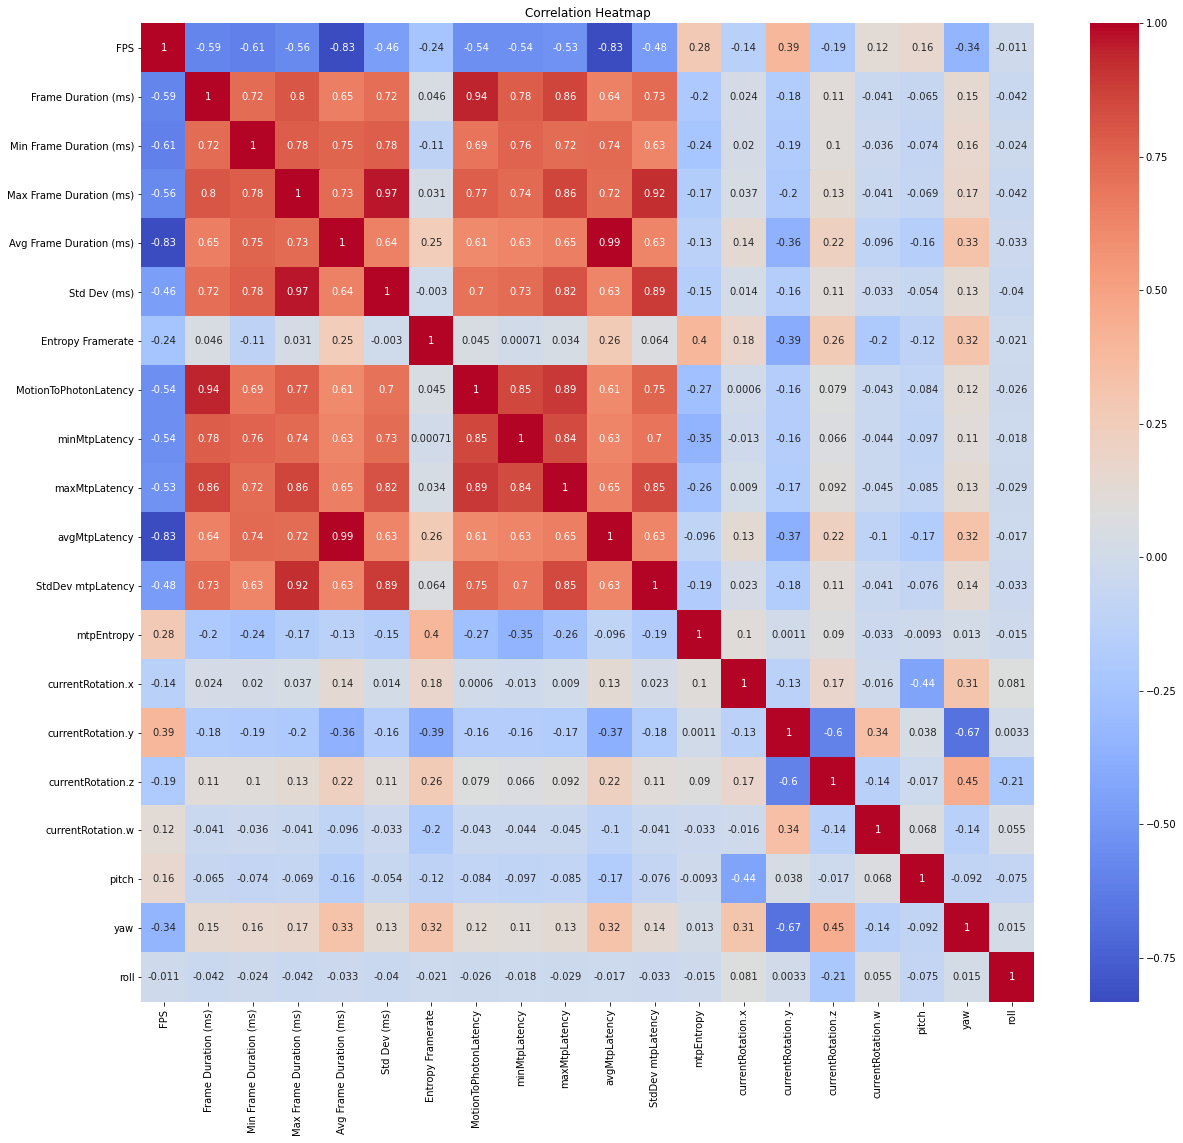

In [35]:
plt.figure(figsize=(20, 18))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title('Correlation Heatmap')
plt.show()

In [25]:
# Create a pairplot of the selected features

<Figure size 1008x864 with 0 Axes>

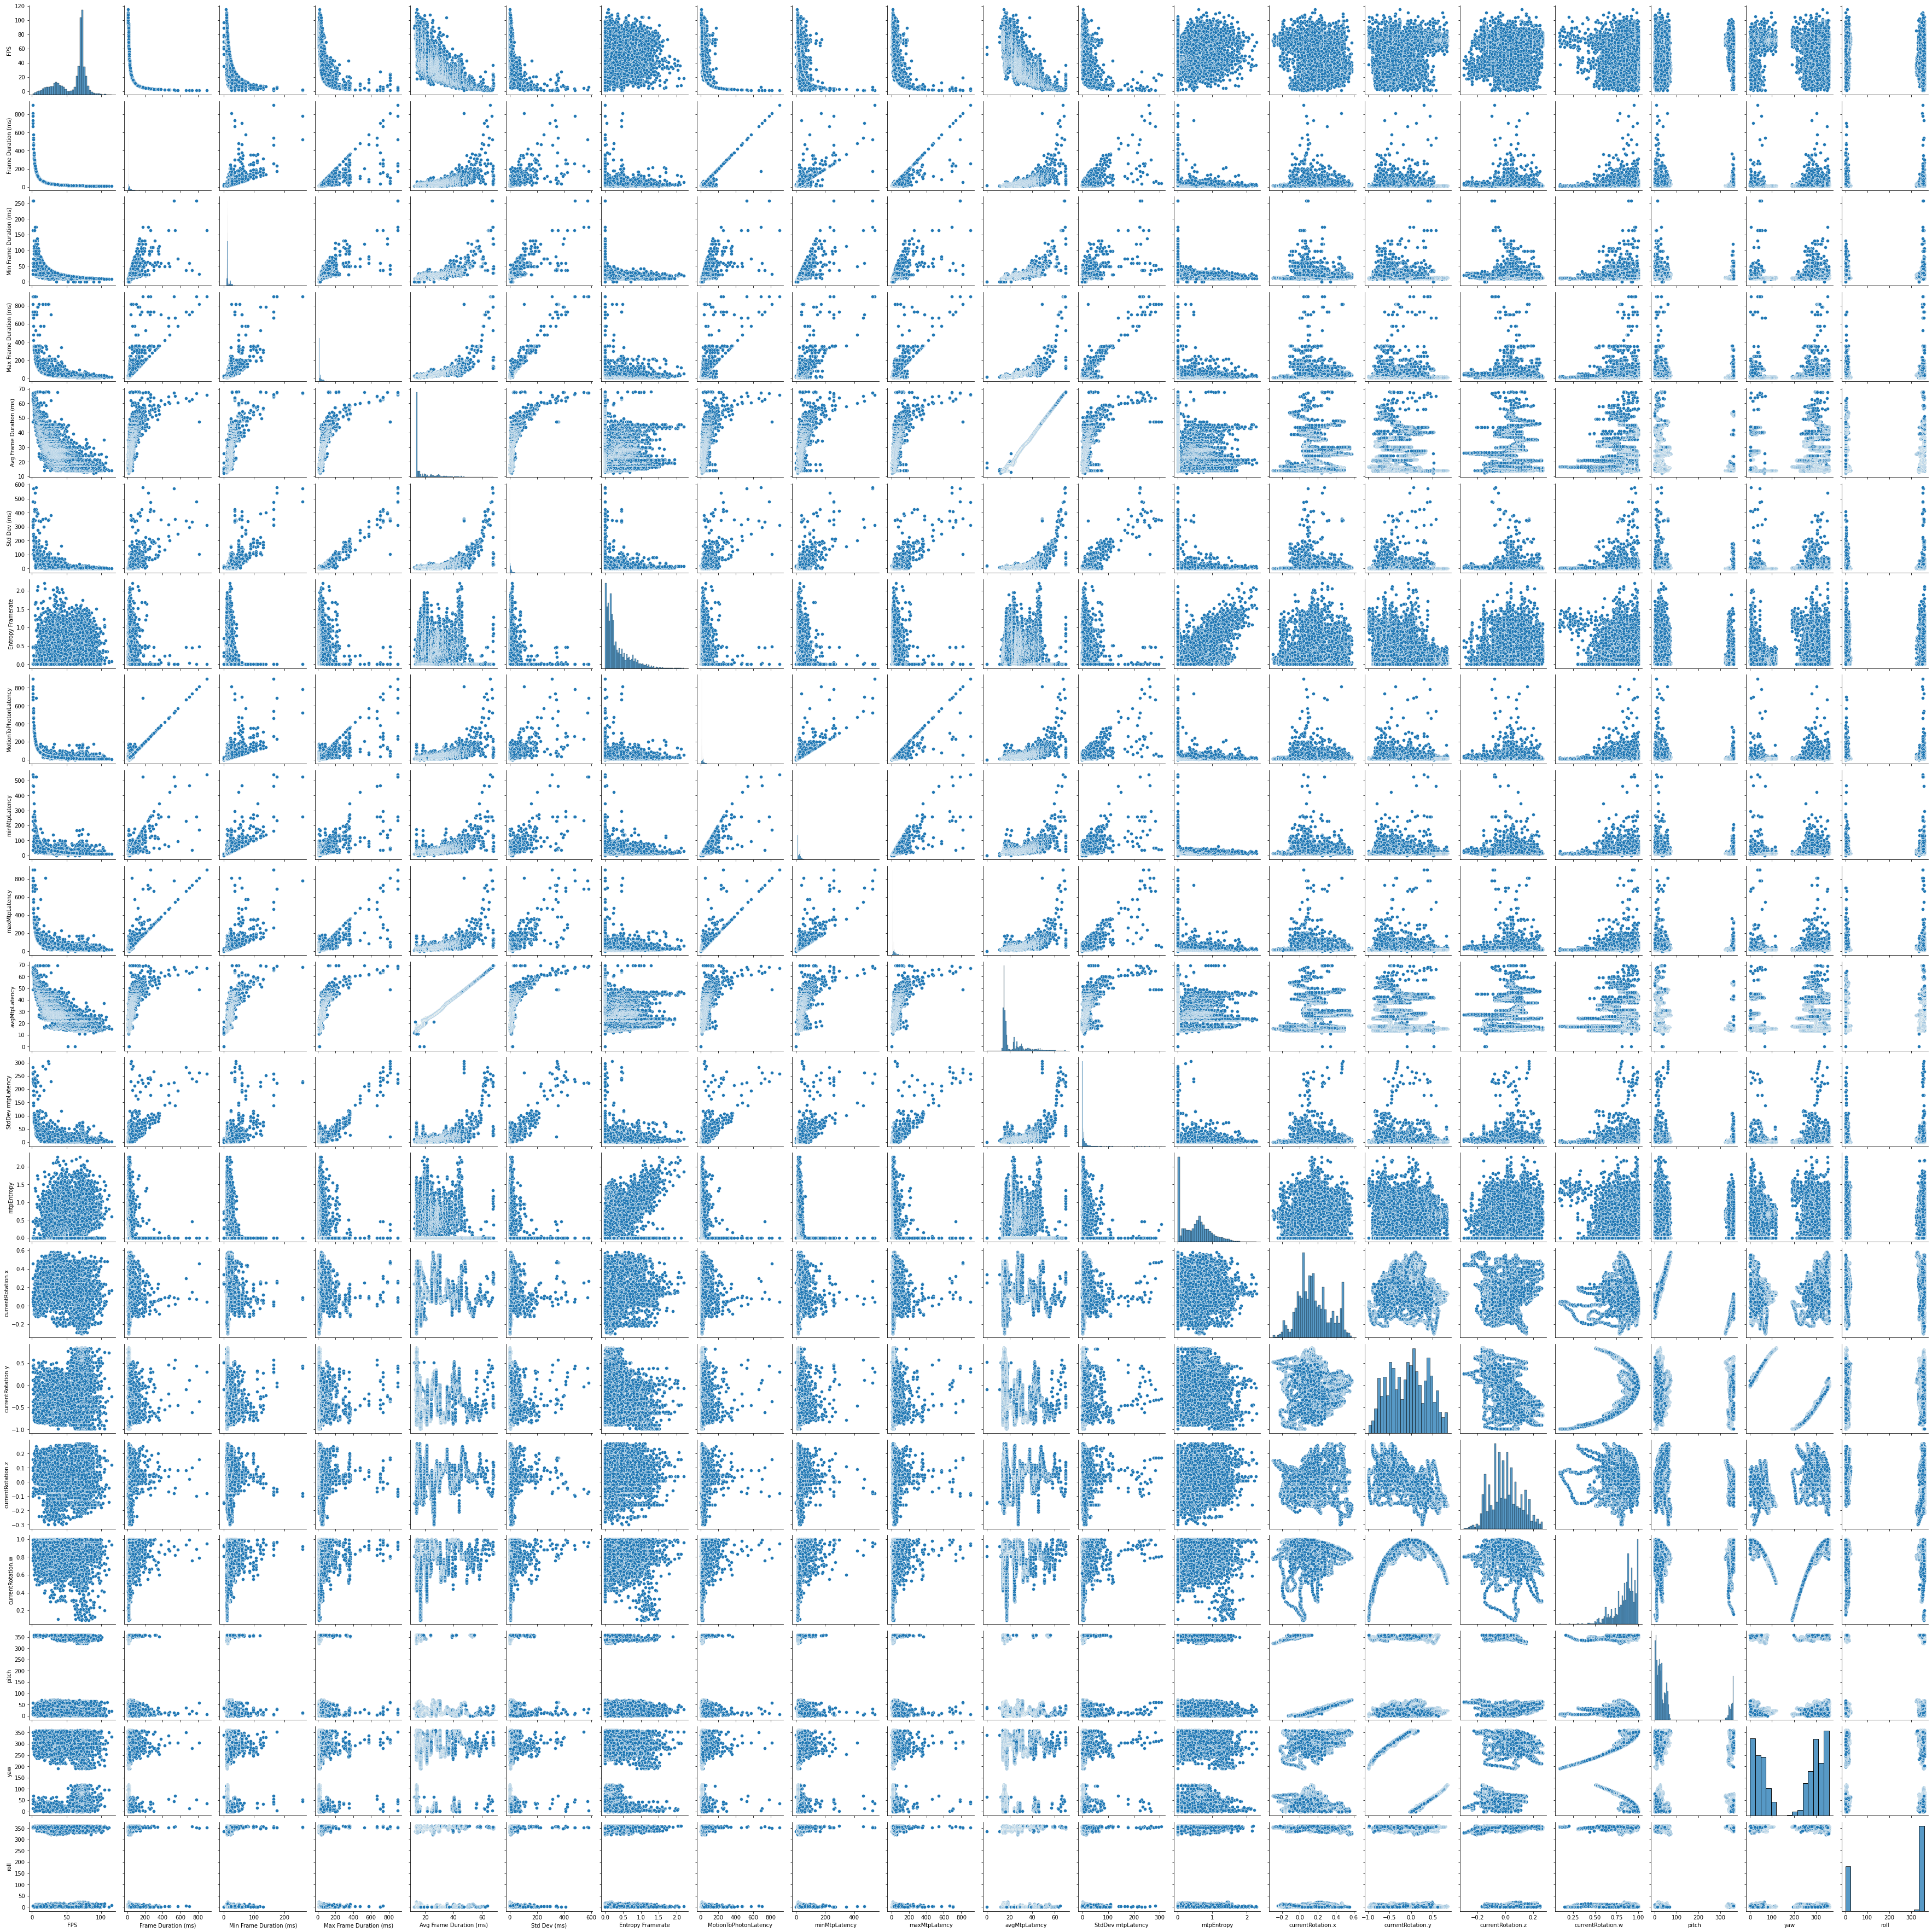

In [34]:
plt.figure(figsize=(14, 12))
sns.pairplot(selected_df)
plt.show()

In [27]:
# Filter heatmap based on correlation threshold value

In [28]:
corr_threshold = 0.9
mask = np.triu(np.ones_like(corr, dtype=bool))
corr_masked = corr.mask(mask)
df_corr_filtered = corr_masked[(corr_masked.abs() <= corr_threshold) & (corr_masked != 1)].dropna(how='all').fillna('')

In [29]:
df_corr_filtered

,FPS,Frame Duration (ms),Min Frame Duration (ms),Max Frame Duration (ms),Avg Frame Duration (ms),Std Dev (ms),Entropy Framerate,MotionToPhotonLatency,minMtpLatency,maxMtpLatency,avgMtpLatency,StdDev mtpLatency,mtpEntropy,currentRotation.x,currentRotation.y,currentRotation.z,currentRotation.w,pitch,yaw,roll
Frame Duration (ms),-0.586990,,,,,,,,,,,,,,,,,,,
Min Frame Duration (ms),-0.610255,0.724094,,,,,,,,,,,,,,,,,,
Max Frame Duration (ms),-0.561651,0.80035,0.780102,,,,,,,,,,,,,,,,,
Avg Frame Duration (ms),-0.830281,0.651505,0.749704,0.73282,,,,,,,,,,,,,,,,
Std Dev (ms),-0.463848,0.718729,0.775406,,0.643764,,,,,,,,,,,,,,,
Entropy Framerate,-0.244172,0.0461515,-0.112107,0.0308087,0.252899,-0.00299842,,,,,,,,,,,,,,
MotionToPhotonLatency,-0.543895,,0.694972,0.771187,0.613301,0.70286,0.0446829,,,,,,,,,,,,,
minMtpLatency,-0.540277,0.779242,0.757674,0.741253,0.632874,0.727599,0.000710485,0.852063,,,,,,,,,,,,
maxMtpLatency,-0.531686,0.856885,0.721717,0.857016,0.653723,0.819703,0.0344578,0.892922,0.83552,,,,,,,,,,,
avgMtpLatency,-0.832302,0.643451,0.741163,0.72365,,0.634543,0.263064,0.611238,0.632482,0.650763,,,,,,,,,,


In [30]:
corr_filtered = corr_masked[(corr_masked.abs() <= corr_threshold) & (corr_masked != 1)].dropna(how='all').fillna(0)

In [31]:
#corr_filtered 

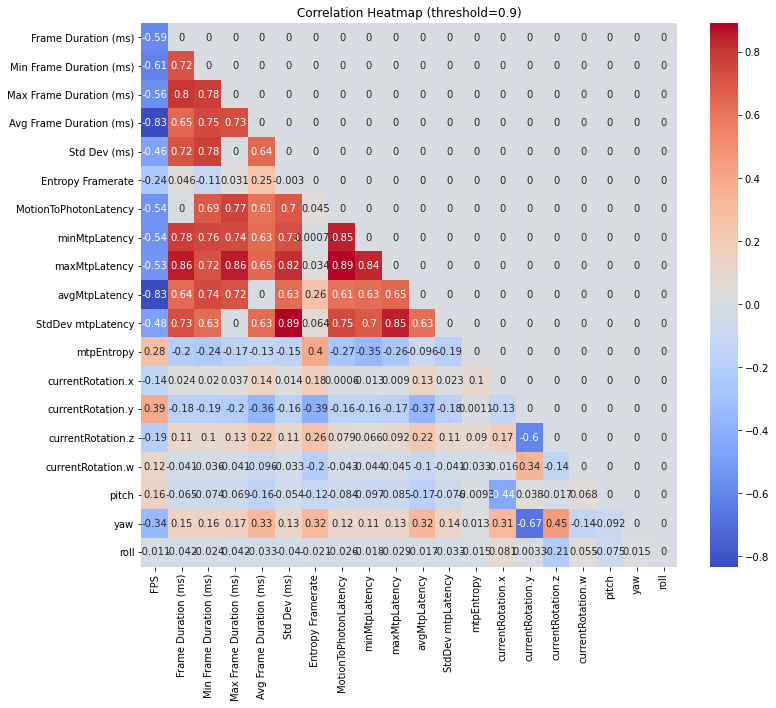

In [32]:
plt.figure(figsize=(12, 10))
sns.heatmap(corr_filtered, annot=True, cmap="coolwarm")
plt.title('Correlation Heatmap (threshold={})'.format(corr_threshold))
plt.show()